### 🤖 Guía de Asistencia con IA: IA como Copiloto de Programación

En esta notebook, utilizaremos la Inteligencia Artificial como copiloto de aprendizaje. Aquí tienes algunas sugerencias de cómo interactuar con un asistente de IA (como Gemini o ChatGPT):

- **Explicación de código**: Si encuentras una función o línea que no comprendes, pregúntale a la IA: *'Explica qué hace esta función línea por línea en Python: [pega tu código]'*.
- **Corrección de errores**: Si tienes un error al ejecutar, copia el error completo y pregúntale: *'¿Por qué este código genera este error y cómo lo soluciono? [pega tu código y error]'*.
- **Optimización**: Pregunta: *'¿Cómo puedo escribir este código de forma más eficiente y limpia?'*.


# Programa Ingenias+ Data Science




## Analisis Exploratorio de un Dataset

Esta notebook les permitiria ejercitar los conceptos de Pandas 🐼  y Análisis exploratorio de datos 📊 que aprendimos hasta ahora. Vamos a trabajar con un dataset que contiene datos relativos a [clientes de un centro comercial](https://www.kaggle.com/akram24/mall-customers). En el Drive esta descargado el archivo. Si tenes inconvenientes o  ese archivo no funciona podes descargarlo directamente de la página web.

### 🔬 Comenzando el proyecto 🎉

Es tu primer dia como Data Scientist. Tu primer proyecto consiste en hacer un análisis de datos sobre clientes de un centro comercial para luego hacer una predicción de ventas o un analisis de cluster. Antes que nada, debes inspeccionar y visualizar tu dataset para saber con que datos estas trabajando.

Como mencionamos durante la clase, una de las primeras cosas que debe realizar un Data Scientist al iniciar un nuevo proyecto es conocer el dataset con el cual va a trabajar. Este paso se conoce como _"Analisis exploratorio de los datos"_.

Además de obtener que tipo de datos contiene el dataset, estadistica descriptiva, detectar problemas como valores faltantes, establecer que tipo de relación existe entre las distintas variables, también debemos visualizar los datos. Este análisis nos permitira hacernos preguntas que puedan ser contestadas con el dataset como así plantear estrategias para poder resolver problemas presentes en él.

#### IMPORTA LAS LIBRERIAS NECESARIAS

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
data = pd.read_csv('/content/drive/MyDrive/NOTEBOOKS 2026/clientes_mall.csv')

**_Lee los datos que se encuentran en el archivo `clientes_mall.csv`. Guardalos en un DataFrame._**

In [5]:
data=pd.read_csv('/content/drive/MyDrive/NOTEBOOKS 2026/clientes_mall.csv')

#### INSPECCIONA LOS DATOS

Primero obtene una visión general del dataset:


🤔 &nbsp; **_¿Como se ven las primeras 5 filas? ¿Cuantas filas y columnas posee? ¿Que tipos de datos contiene cada una de las columnas?_**

In [6]:
data.head(5)

,Unnamed: 0,CustomerID,Genre,Age,Annual Income (k$),Spending Score (1-100)
0,0,1.0,Male,19.0,15.0,39.0
1,1,2.0,NaN,21.0,15.0,81.0
2,2,3.0,Female,20.0,16.0,6.0
3,3,4.0,Female,23.0,16.0,77.0
4,4,5.0,NaN,31.0,17.0,40.0


In [7]:
data.shape

(200, 6)

In [8]:
data.dtypes

,0
Unnamed: 0,int64
CustomerID,float64
Genre,object
Age,float64
Annual Income (k$),float64
Spending Score (1-100),float64


In [ ]:
data

,Unnamed: 0,CustomerID,Genre,Age,Annual Income (k$),Spending Score (1-100)
0,0,1.0,Male,19.0,15.0,39.0
1,1,2.0,NaN,21.0,15.0,81.0
2,2,3.0,Female,20.0,16.0,6.0
3,3,4.0,Female,23.0,16.0,77.0
4,4,5.0,NaN,31.0,17.0,40.0
...,...,...,...,...,...,...
195,195,196.0,NaN,35.0,120.0,79.0
196,196,197.0,Female,45.0,126.0,28.0
197,197,198.0,Male,32.0,126.0,74.0
198,198,199.0,Male,32.0,137.0,18.0


In [43]:
#data["Age"][data["Age"]>25 & data["Age"]<40]

**_Hay algunas columnas que tienen nombres incomodos (ej. `Spending Score (1-100)` y `Annual Income (k$)`). Renombra esas columnas_**

In [44]:
data.rename(columns={
    'Annual Income (k$)': 'Ingreso_anual',
    'Spending Score (1-100)' : 'Puntuación_gasto'}, inplace = True)


In [46]:
data.head(5)

,CustomerID,Genre,Age,Ingreso_anual,Puntuación_gasto
0,1.0,Male,19.0,15.0,39.0
2,3.0,Female,20.0,16.0,6.0
3,4.0,Female,23.0,16.0,77.0
5,6.0,Female,22.0,17.0,76.0
7,8.0,Female,23.0,18.0,94.0


#### Valores faltantes

🤔 &nbsp; **_¿Hay valores faltantes en alguna de las columnas?_**

In [47]:
data.isna().sum()

,0
CustomerID,0
Genre,0
Age,0
Ingreso_anual,0
Puntuación_gasto,0


**_Elimina todas las filas que tengan valores faltantes_**

In [48]:
data.dropna(inplace=True)

#### FILTRA LOS DATOS

Porque tu compañia quiere diseñar un a campaña de marketing especial para personas entre 25 y 40 años, vamos a analizar los datos solo para estos clientes.

🤔 &nbsp; **_Chequea que categorias aparecen en la columna `Age`_**.

In [49]:
data['Age'].unique()

array([19., 20., 23., 22., 30., 67., 35., 58., 24., 37., 25., 31., 54.,
       29., 45., 40., 60., 49., 42., 36., 50., 27., 33., 59., 47., 53.,
       70., 63., 18., 68., 32., 26., 57., 38., 46., 21., 48., 34., 66.,
       65., 51., 43., 39., 44., 28., 41.])

**_Filtra los datos para quedarte unicamente con las filas que correspondan a personas entre 25 y 40 años. Guardalo en una variable que se llame `clientes_seleccionados`._**

In [50]:
data_age = data[(data['Age']>25) & (data['Age']<40)]

In [51]:
data_age['Age'].unique()

array([30., 35., 37., 31., 29., 36., 27., 33., 32., 26., 38., 34., 39.,
       28.])

**_Reiniciamos el indice usando `reset_index()` para que las filas vuelvan a ser numeradas a partir de 0. `drop=True` permite descartar los indices anteriores y no guardarlos como una nueva columna. `inplace=True` permite que se modifique el DataFrame original._**

In [52]:
data_age.reset_index(drop=True, inplace = True)

In [53]:
data_age.head(5)

,CustomerID,Genre,Age,Ingreso_anual,Puntuación_gasto
0,10.0,Female,30.0,19.0,72.0
1,12.0,Female,35.0,19.0,99.0
2,15.0,Male,37.0,20.0,13.0
3,17.0,Female,35.0,21.0,35.0
4,20.0,Female,35.0,23.0,98.0


**_Obtene estadistica descriptiva para las columnas que corresponden al salario anual y puntaje de gastos de las personas entre 25 y 40 años. Lo importante es que se muestre promedio, mediana, desvio estandard, valores minimos y maximos._**

In [77]:
print('Ingreso Anual:', data_age['Ingreso_anual'].describe())
print('Puntuación gasto:', data_age['Puntuación_gasto'].describe())


Ingreso Anual: count     52.000000
mean      68.211538
std       29.927584
min       19.000000
25%       42.750000
50%       73.000000
75%       87.000000
max      137.000000
Name: Ingreso_anual, dtype: float64
Puntuación gasto: count    52.000000
mean     58.673077
std      28.227174
min       1.000000
25%      41.500000
50%      64.500000
75%      82.250000
max      99.000000
Name: Puntuación_gasto, dtype: float64


In [66]:
print(
  data_age['Ingreso_anual'].mean(),
  data_age['Ingreso_anual'].median(),
  data_age['Ingreso_anual'].std(),
  data_age['Ingreso_anual'].min(),
  data_age['Ingreso_anual'].max(),
  data_age['Puntuación_gasto'].mean(),
  data_age['Puntuación_gasto'].median(),
  data_age['Puntuación_gasto'].std(),
  data_age['Puntuación_gasto'].min(),
  data_age['Puntuación_gasto'].max())

68.21153846153847 73.0 29.927583537770907 19.0 137.0 58.67307692307692 64.5 28.22717447039647 1.0 99.0


🤔 &nbsp; De acuerdo a los valores **_¿Cuál es el sueldo promedio de estos clientes? ¿Cual es el puntaje de gastos mediano en el grupo? ¿Crees que son buenas medidas para caracterizar el grupo?_**

**_Compara estos valores con aquellos de los clientes en general._**

In [73]:
data['Ingreso_anual'].mean()

np.float64(60.76258992805755)

In [74]:
data_age['Ingreso_anual'].mean()

np.float64(68.21153846153847)

**_Obtiene la edad promedio de clientes que tienen un sueldo mayor al promedio._**

In [81]:
edad_sueldo_alto_2540 = data_age[data_age['Ingreso_anual']>data_age['Ingreso_anual'].mean()]['Age']
edad_sueldo_alto_2540.mean()

np.float64(32.63333333333333)

**_Compara estos valores con aquellos de los clientes en general._**

In [82]:
edad_sueldo_alto = data[data['Ingreso_anual']>data['Ingreso_anual'].mean()]['Age']
edad_sueldo_alto.mean()

np.float64(39.4)

🤔 &nbsp; **_¿Qué otras preguntas te surgen para analizar en este dataset?_**

#### VISUALIZA LOS DATOS

**_Visualiza la distribución de las variables de sueldo promedio y puntaje de gastos. Haz gráficos que superpongan la distribución de cada una de estas variables de manera global como también sólo para los clientes seleccionados._**

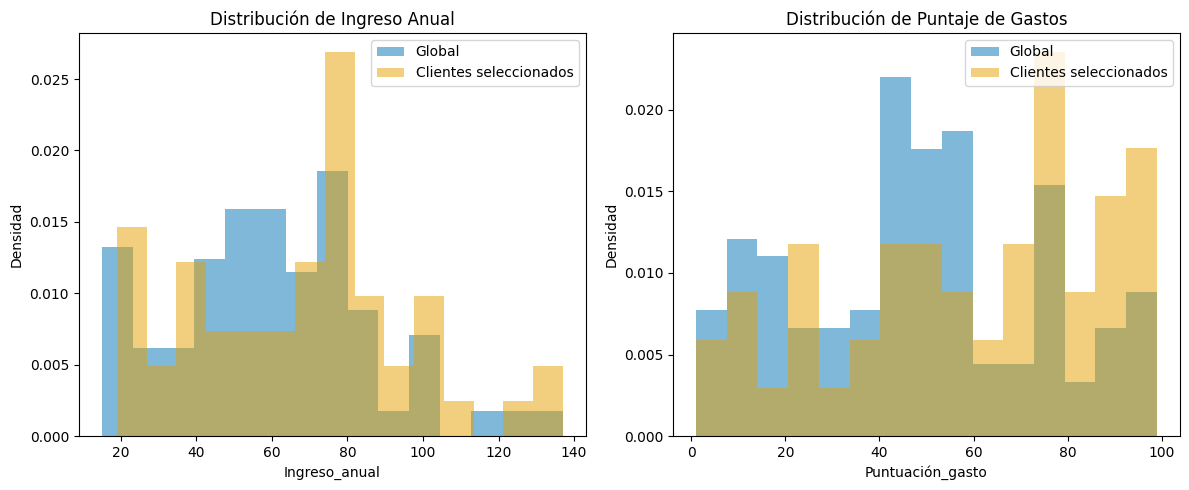

In [89]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

variables = ['Ingreso_anual', 'Puntuación_gasto']
titulos = ['Distribución de Ingreso Anual', 'Distribución de Puntaje de Gastos']

for ax, var, titulo in zip(axes, variables, titulos):
    ax.hist(data[var], bins=15, density=True, alpha=0.5,
             color='#0072B2', label='Global')
    ax.hist(data_age[var], bins=15, density=True, alpha=0.5,
             color='#E69F00', label='Clientes seleccionados')
    ax.set_title(titulo)
    ax.set_xlabel(var)
    ax.set_ylabel('Densidad')
    ax.legend()

plt.tight_layout()
plt.show()

**_Agrupa los datos por la variable `Genre` para ambos casos. Gráfica el ingreso promedio y su dispersion. Grafica, luego, el ingreso mediano y su rango intercuartil._**

🤔 &nbsp; **_¿Existe una correlación entre el sueldo anual y el puntaje de gastos en los clientes seleccionados? ¿Y en todos los clientes en general?_**

**_Visualiza otros datos que creas relevantes para este analisis._**

#### 💾 &nbsp; GUARDANDO EL ARCHIVO PARA LOS SIGUIENTES PASOS

Los siguientes pasos que vamos a tomar implican la transformación de los datos presentes en el dataset para un correcto ajuste de un modelo a elección. Para no tener que correr nuevamente todo el código, podemos guardar en un archivo `csv` el dataset tal cual lo tenemos ahora.

1) **Utiliza la función `.to_csv()` para guardar tu dataset**. Antes de hacerlo chequea la [documentación](https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.DataFrame.to_csv.html).